# Lab 1-08：LiteLLM 統一介面，順便算清楚每次呼叫花多少錢

**目標**：用 LiteLLM 的 `completion()` 一個函式呼叫 Ollama、OpenAI、OpenRouter、Anthropic；用 `Router` 做「雲端失敗退回本地」；
再把 API 費用算清楚：從單價表算出一次呼叫多少錢、對照實際帳單上的 `usage`，最後寫一個超過預算就停的追蹤器。

**你會學到**
- LiteLLM 怎麼用「`供應商/模型`」一個字串切換供應商，回傳格式和錯誤型別都統一成 OpenAI 的樣子
- `Router` 的 fallback，和 Lab 1-05 手寫的雙軌客戶端做同一件事
- 費用＝輸入 token × 輸入單價＋輸出 token × 輸出單價；`litellm.model_cost` 查價、`completion_cost()` 算單次
- 中文 vs 英文、輸入 vs 輸出、長對話——錢花在哪裡
- 推理模型的「看不到的輸出」：推理 token 照輸出計費，`reasoning_effort` 怎麼調
- LiteLLM Proxy（gateway）是什麼

**前置**：先讀 `00_concepts.md` 第 8 節（API 怎麼計費）；Ollama 有在跑（Lab 1-04）。
雲端都是選填，在 `.env` 填了才呼叫：`OPENAI_API_KEY`、`OPENROUTER_API_KEY`、`ANTHROPIC_API_KEY`。
有 OpenAI 金鑰時，整本最多打 8 次雲端、用 OpenAI 最便宜的 `gpt-5.4-nano`，總花費不到 0.01 美元。

**對應投影片**：「換供應商只換網址」「開放權重與商業 API」

![LiteLLM 架構：你的程式呼叫 completion() 或 Router，依前綴分派到 Ollama、OpenAI、OpenRouter、Anthropic，失敗就換下一個，回來的是統一格式加上費用](images/litellm_router.jpg)

*圖：模型名稱的前綴（`ollama/`、`openai/`…）決定送去哪一家；LiteLLM 負責翻譯請求格式，回來一律是 OpenAI 的格式，並附上這次的費用。
`Router` 再多做一件事：一家失敗就換下一家（朱紅虛線）。*

## Step 1：一個函式，先打本機 Ollama

Lab 1-07 看過：各家 API 格式不完全一樣，Anthropic 甚至要先轉換。LiteLLM 把這層轉換做好了，
你只寫 `completion(model="供應商/模型", messages=...)`。

In [1]:
import os
import time

import litellm
from dotenv import load_dotenv
from litellm import completion

load_dotenv()
litellm.suppress_debug_info = True  # 錯誤時不要印一大段除錯提示

OLLAMA_BASE = os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1").removesuffix("/v1")
LOCAL = "ollama/" + os.getenv("LOCAL_MODEL", "qwen2.5:3b")

question = [{"role": "user", "content": "用一句話介紹索隆。"}]
r = completion(model=LOCAL, messages=question, api_base=OLLAMA_BASE, temperature=0)
print(type(r).__name__)
print(r.choices[0].message.content)
print(r.usage)

ModelResponse
索隆是一位坚定的海贼，目标是收集所有ONE PIECE，以实现和平的航海生活。
Usage(completion_tokens=24, prompt_tokens=39, total_tokens=63, completion_tokens_details=None, prompt_tokens_details=None)


回傳的物件長得跟 OpenAI SDK 一模一樣：`choices[0].message.content`、`usage.prompt_tokens`。
模型名稱的 `ollama/` 告訴 LiteLLM 這是 Ollama；`api_base` 是 Ollama 的位址（不含 `/v1`）。

這個寫法你在模組 5 會再看到：CrewAI 底層就是 LiteLLM，所以 M5-09 寫 `LLM(model="ollama/qwen2.5:3b")`，前綴規則完全一樣。

## Step 2：同一個函式打四家

把四家供應商列成表，迴圈打過去。沒金鑰的自動跳過；雲端呼叫都經過 `cloud_completion`，它會數次數，最多 8 次。

In [2]:
CLOUD_MODEL = "gpt-5.4-nano"  # 2026-03 發布，OpenAI 最便宜的一級；GPT-5 系列是推理模型，Step 8 會看它的推理 token
MAX_CLOUD_CALLS = 8
has_cloud = bool(os.getenv("OPENAI_API_KEY"))  # Step 7、8 的雲端呼叫要有這把金鑰
cloud_calls = []  # 每次雲端呼叫的回應都記下來，最後對帳


def cloud_completion(**kwargs):
    if len(cloud_calls) >= MAX_CLOUD_CALLS:
        raise RuntimeError(f"本 notebook 最多打 {MAX_CLOUD_CALLS} 次雲端")
    resp = completion(timeout=30, num_retries=0, **kwargs)
    cloud_calls.append(resp)
    return resp


PROVIDERS = [
    {"name": "Ollama", "model": LOCAL, "key_env": None, "extra": {"api_base": OLLAMA_BASE}},
    {"name": "OpenAI", "model": f"openai/{CLOUD_MODEL}", "key_env": "OPENAI_API_KEY", "extra": {}},
    {"name": "OpenRouter", "model": f"openrouter/openai/{CLOUD_MODEL}", "key_env": "OPENROUTER_API_KEY", "extra": {}},
    {"name": "Anthropic", "model": "anthropic/claude-haiku-4-5", "key_env": "ANTHROPIC_API_KEY", "extra": {}},
]

results = {}
for p in PROVIDERS:
    if p["key_env"] and not os.getenv(p["key_env"]):
        print(f"{p['name']:<11} 略過（沒有 {p['key_env']}）")
        continue
    call = completion if p["key_env"] is None else cloud_completion
    t = time.time()
    resp = call(model=p["model"], messages=question, max_tokens=60, temperature=0, **p["extra"])
    results[p["name"]] = resp
    print(f"{p['name']:<11} {time.time() - t:4.1f}s  {resp.usage.prompt_tokens:>3} 進 {resp.usage.completion_tokens:>3} 出  "
          f"{resp.choices[0].message.content[:40]}")

Ollama       0.3s   39 進  24 出  索隆是一位坚定的海贼，誓言消灭所有恶魔果实持有者，以正义和勇气为信念。
OpenAI       1.4s   13 進  42 出  索隆是《海賊王》中的劍士，憑藉三刀流與堅定意志，立志成為世界第一大劍豪。
OpenRouter  略過（沒有 OPENROUTER_API_KEY）
Anthropic   略過（沒有 ANTHROPIC_API_KEY）


四家的請求格式其實不同（Anthropic 的 system 要放外面、`max_tokens` 必填；OpenAI 的 GPT-5 系列不收 `max_tokens`、要寫 `max_completion_tokens`），
但你的程式碼一行都不用改：LiteLLM 依模型把 `max_tokens` 翻成各家要的名稱。
這就是「統一介面」的價值：換模型只是換一個字串，可以寫在設定檔或環境變數裡。

模型也會下架：這本原本用 `gpt-4.1-nano`，執行時它已被 OpenAI 停用，回的是 `NotFoundError`。模型名稱放在一個地方（這裡是 `CLOUD_MODEL`），換掉只改一行。

## Step 3：統一的回傳格式

不管哪一家，取答案、取 token 數、取結束原因的路徑都一樣。這次花多少錢，用公開函式 `litellm.completion_cost()` 算：
它讀回應裡的模型名稱和 `usage`，查內建價目表相乘。

> 舊版寫法 → 新版寫法：網路上很多範例讀 `resp._hidden_params["response_cost"]`。底線開頭是私有屬性，
> 隨時可能改名或拿掉；用公開的 `completion_cost(completion_response=resp)`，結果相同、也比較不會壞。

In [3]:
for name, resp in results.items():
    print(f"{name:<8} model={resp.model:<28} finish={resp.choices[0].finish_reason:<6} "
          f"tokens={resp.usage.total_tokens:<4} 費用=${litellm.completion_cost(completion_response=resp):.8f}")

Ollama   model=ollama/qwen2.5:3b            finish=stop   tokens=63   費用=$0.00000000
OpenAI   model=gpt-5.4-nano-2026-03-17      finish=stop   tokens=55   費用=$0.00005510


Ollama 的費用是 0（本機跑，不收錢）；雲端的費用是 LiteLLM 用內建價目表算出來的。Step 7 會手算一次對帳。

## Step 4：統一的錯誤型別

各家 SDK 的錯誤類別都不一樣。LiteLLM 把它們對應成同一套，而且繼承自 OpenAI SDK 的錯誤類別，
所以 Lab 1-05 那種 `except OpenAIError` 的寫法照樣接得住。故意做兩個錯：

In [4]:
from litellm.exceptions import APIConnectionError, NotFoundError

broken = [
    ("Ollama 沒開（port 錯）", dict(model=LOCAL, api_base="http://localhost:9")),
    ("模型名稱打錯", dict(model="ollama/qwen9:99b", api_base=OLLAMA_BASE)),
]
for label, kwargs in broken:
    try:
        completion(messages=question, num_retries=0, **kwargs)
    except (APIConnectionError, NotFoundError) as exc:
        chain = " → ".join(c.__module__.split(".")[0] + "." + c.__name__ for c in type(exc).__mro__[:3])
        print(f"{label}：{chain}")
        print(f"   {str(exc)[:90]}")

Ollama 沒開（port 錯）：litellm.APIConnectionError → openai.APIConnectionError → openai.APIError
   litellm.APIConnectionError: OllamaException - [Errno 111] Connection refused
模型名稱打錯：litellm.NotFoundError → openai.NotFoundError → openai.APIStatusError
   litellm.NotFoundError: OllamaException - {"error":"model 'qwen9:99b' not found"}


連不上是 `APIConnectionError`（可以換下一家）、模型不存在是 `NotFoundError`（換家也沒用，是設定錯了）。
其他常見的還有 `AuthenticationError`（金鑰錯）、`RateLimitError`（被限流，等一下再試）、`ContextWindowExceededError`（prompt 太長）。
錯誤分得清楚，fallback 才知道什麼時候該換、什麼時候該直接報錯。

## Step 5：`Router`——雲端失敗自動退回本地

Lab 1-05 手寫了大約 30 行的雙軌客戶端。LiteLLM 的 `Router` 用設定表達同一件事：
每個「部署」取一個名字，`fallbacks` 寫「這個失敗就換那個」。這裡故意把雲端的位址寫錯，看它退回本地。
壞掉的雲端在連線階段就失敗，不會產生費用，所以沒有金鑰也能跑。

In [5]:
from litellm import Router

router = Router(
    model_list=[
        {"model_name": "cloud", "litellm_params": {  # 故意壞掉的雲端：位址指到沒人在聽的 port
            "model": f"openai/{CLOUD_MODEL}", "api_base": "http://localhost:9/v1", "api_key": "demo"}},
        {"model_name": "local", "litellm_params": {"model": LOCAL, "api_base": OLLAMA_BASE}},
    ],
    fallbacks=[{"cloud": ["local"]}],
    num_retries=0,
    timeout=30,
)

t = time.time()
resp = router.completion(model="cloud", messages=[{"role": "user", "content": "用一句話介紹娜美。"}], max_tokens=60)
print(f"實際回答的是：{resp.model}（{time.time() - t:.1f}s）")
print(resp.choices[0].message.content)

實際回答的是：gpt-5.4-nano-2026-03-17（1.7s）
娜美是《海賊王》中聰明能幹、擅長航海與制圖的航海士，同時也懷抱成為偉大海圖繪製者的夢想。


對照 Lab 1-05：

| | 手寫雙軌客戶端 | LiteLLM `Router` |
|---|---|---|
| 端點清單 | `Endpoint` dataclass | `model_list` |
| 依序試 | 自己寫 `for` 迴圈和 `try` | `fallbacks` 一行設定 |
| 重試、逾時、冷卻 | 要自己加 | `num_retries`、`timeout`、壞掉的部署會暫停一陣子 |
| 負載平衡 | 沒有 | 同名的多個部署會輪流用 |

手寫一次是為了懂原理；實務上這種通用邏輯交給套件。本課的 `course_utils/llm.py` 保持手寫，是因為它短、沒有額外依賴，而且你看得懂每一行。

## Step 6：查價目表

雲端 API 按 token 收費，**輸入和輸出分開計價**。LiteLLM 內建一張價目表 `litellm.model_cost`（幾千個模型），
單位是「每個 token 幾美元」；人比較常講「每百萬 token 幾美元」，乘上 1,000,000 就是。

In [6]:
COMPARE = ["gpt-5.4-nano", "gpt-4o-mini", "gpt-4.1-mini", "deepseek/deepseek-chat", "claude-haiku-4-5", "gpt-4o", "claude-sonnet-4-5"]

prices = {}
print(f"{'模型':<24}{'輸入':>8}{'快取輸入':>10}{'輸出':>8}   （美元／百萬 token）")
for m in COMPARE:
    c = litellm.model_cost[m]
    prices[m] = (c["input_cost_per_token"] * 1e6, (c.get("cache_read_input_token_cost") or 0) * 1e6, c["output_cost_per_token"] * 1e6)
    print(f"{m:<24}{prices[m][0]:>8.2f}{prices[m][1]:>10.3f}{prices[m][2]:>8.2f}   輸出是輸入的 {prices[m][2] / prices[m][0]:.1f} 倍")

模型                            輸入      快取輸入      輸出   （美元／百萬 token）
gpt-5.4-nano                0.20     0.020    1.25   輸出是輸入的 6.3 倍
gpt-4o-mini                 0.15     0.075    0.60   輸出是輸入的 4.0 倍
gpt-4.1-mini                0.40     0.100    1.60   輸出是輸入的 4.0 倍
deepseek/deepseek-chat      0.28     0.028    0.42   輸出是輸入的 1.5 倍
claude-haiku-4-5            1.00     0.100    5.00   輸出是輸入的 5.0 倍
gpt-4o                      2.50     1.250   10.00   輸出是輸入的 4.0 倍
claude-sonnet-4-5           3.00     0.300   15.00   輸出是輸入的 5.0 倍


價目表跟著 LiteLLM 版本走，每次 import 也會試著從網路抓最新版。真的要算帳，以供應商官網價格為準。

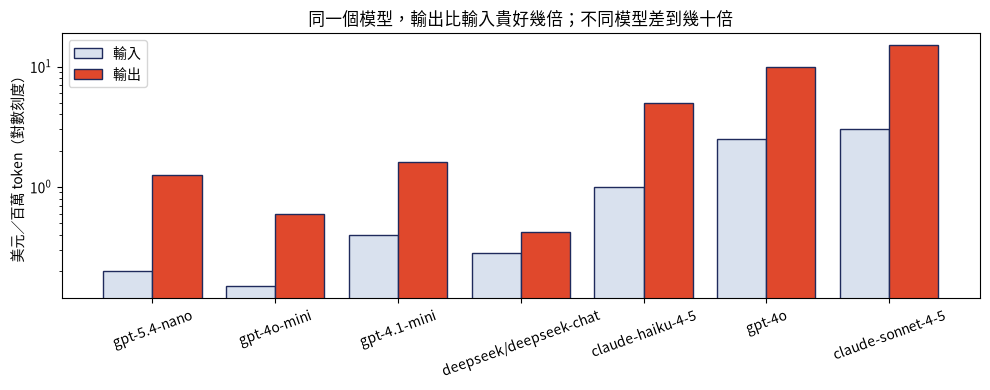

In [7]:
import matplotlib.pyplot as plt
import numpy as np

from course_utils.viz import setup_cjk

setup_cjk()

x = np.arange(len(COMPARE))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, [prices[m][0] for m in COMPARE], 0.4, label="輸入", color="#d9e1ee", edgecolor="#1f2a5c")
ax.bar(x + 0.2, [prices[m][2] for m in COMPARE], 0.4, label="輸出", color="#e0482c", edgecolor="#1f2a5c")
ax.set_xticks(x, COMPARE, rotation=20)
ax.set_yscale("log")
ax.set_ylabel("美元／百萬 token（對數刻度）")
ax.set_title("同一個模型，輸出比輸入貴好幾倍；不同模型差到幾十倍")
ax.legend()
plt.tight_layout()
plt.show()

## Step 7：手算一次，跟帳單對帳

公式只有一行：

```
費用 = prompt_tokens × 輸入單價 + completion_tokens × 輸出單價
```

用同一個問題的中文版和英文版各打一次雲端，拿回應裡的 `usage` 手算，再跟 `completion_cost()` 比。

In [8]:
def hand_cost(model: str, prompt_tokens: int, completion_tokens: int) -> float:
    c = litellm.model_cost[model]
    return prompt_tokens * c["input_cost_per_token"] + completion_tokens * c["output_cost_per_token"]


PAIR = {
    "中文": "請用三句話說明草帽海賊團為什麼要前往偉大航道，以及他們的船長想找到什麼。",
    "英文": "In three sentences, explain why the Straw Hat Pirates head for the Grand Line and what their captain wants to find.",
}
pair_usage = {}
for lang, text in PAIR.items():
    msgs = [{"role": "user", "content": text}]
    if has_cloud:
        resp = cloud_completion(model=f"openai/{CLOUD_MODEL}", messages=msgs, max_tokens=120, temperature=0)
        pt, ct = resp.usage.prompt_tokens, resp.usage.completion_tokens
        official = litellm.completion_cost(completion_response=resp)
        cached = getattr(resp.usage.prompt_tokens_details, "cached_tokens", 0) or 0
        reasoning = getattr(resp.usage.completion_tokens_details, "reasoning_tokens", 0) or 0
        print(f"{lang}：輸入 {pt}、輸出 {ct}（其中推理 {reasoning}；快取命中 {cached}）")
        print(f"   手算 ${hand_cost(CLOUD_MODEL, pt, ct):.8f}   completion_cost ${official:.8f}")
    else:  # 沒金鑰：用 tokenizer 估輸入，輸出假設 100 token
        pt, ct = litellm.token_counter(model=CLOUD_MODEL, messages=msgs), 100
        print(f"{lang}：估計輸入 {pt}、假設輸出 {ct} → ${hand_cost(CLOUD_MODEL, pt, ct):.8f}")
    pair_usage[lang] = (pt, ct)

中文：輸入 41、輸出 114（其中推理 0；快取命中 0）
   手算 $0.00015070   completion_cost $0.00015070
英文：輸入 29、輸出 79（其中推理 0；快取命中 0）
   手算 $0.00010455   completion_cost $0.00010455


手算和 `completion_cost()` 一樣，因為它做的就是這個乘法。幾個觀察：
- **中文的輸入 token 比英文多**：同樣的意思，中文要多花一些 token（Lab 1-01 看過原因）。
- **輸出才是大頭**：輸出 token 比輸入多，單價又是輸入的好幾倍（`gpt-5.4-nano` 是 6.25 倍），費用大部分落在輸出。
- **快取命中是 0**：OpenAI 要 prompt 超過 1024 token、而且開頭跟最近的請求一樣才會自動快取，命中的部分打折（`gpt-5.4-nano` 只收一折）。
  所以固定不變的 system prompt、工具說明要放在最前面，會變的內容放後面。

## Step 8：推理模型——看不到的輸出也要付錢

上一步的 `completion_tokens` 裡藏了一個欄位：`completion_tokens_details.reasoning_tokens`。GPT-5 系列是**推理模型**，
回答前可以先在內部「想」一段，這段思考你看不到，但**照輸出 token 計費**，也佔 context window。
想多少由 `reasoning_effort` 控制。`gpt-5.4-nano` 支援 `none`、`low`、`medium`、`high`、`xhigh`（不支援 `minimal`），預設是 `none`，
所以上一步的推理 token 是 0。

出一道要算一下的題目，同一題用三種 effort 各打一次（3 次雲端呼叫）：

In [9]:
PUZZLE = [{"role": "user", "content": "草帽海賊團有 10 人，每人每天吃 3 塊肉，但魯夫一個人吃其他人總和的兩倍。航行 7 天至少要帶幾塊肉？只回數字。"}]
ANSWER = "567"  # 其他 9 人每天 27 塊、魯夫 54 塊，每天 81 塊 × 7 天

effort_rows = []
for effort in ["none", "low", "medium"]:
    if not has_cloud:
        print("沒有 OPENAI_API_KEY，略過。")
        break
    resp = cloud_completion(model=f"openai/{CLOUD_MODEL}", messages=PUZZLE, max_tokens=2000, reasoning_effort=effort)
    reasoning = resp.usage.completion_tokens_details.reasoning_tokens or 0
    visible = resp.usage.completion_tokens - reasoning
    answer = resp.choices[0].message.content.strip()
    cost = litellm.completion_cost(completion_response=resp)
    effort_rows.append((effort, reasoning, visible, cost))
    print(f"effort={effort:<7} 推理 {reasoning:>4} + 看得到的 {visible:>3} 輸出 token   ${cost:.6f}   "
          f"回答 {answer}（{'對' if answer == ANSWER else '錯'}）")

effort=none    推理    0 + 看得到的   4 輸出 token   $0.000017   回答 52（錯）
effort=low     推理   63 + 看得到的  10 輸出 token   $0.000103   回答 567（對）
effort=medium  推理  124 + 看得到的  10 輸出 token   $0.000179   回答 567（對）


三個觀察：
- **看得到的輸出只有幾個字，帳單上的輸出卻可以多出好幾倍到幾十倍**：多出來的全是推理 token。用推理模型時，只看回答長度估費用會嚴重低估。
- **effort 越高越貴，但不一定越需要**：簡單的事（介紹角色、抽欄位）用 `none` 就好；要算、要推的題目，`none` 可能直接答錯，`low` 常常就夠。
- **`max_tokens` 要留給推理**：上限同時管推理和回答。設太小，推理就把額度用完，回答可能是空的（`finish_reason == "length"`）。
  這裡給 2000；OpenAI 官方建議剛開始實驗時留更多。

用 OpenAI SDK 直接打時，同一件事的寫法是 `client.chat.completions.create(..., reasoning_effort="low", max_completion_tokens=...)`；
Responses API 則是 `reasoning={"effort": "low"}`、`max_output_tokens=...`，用量在 `usage.output_tokens_details.reasoning_tokens`。

## Step 9：輸入 vs 輸出——叫模型少講一點最省

同一個問題，要求「一句話」和「詳細說明」，輸出長度差很多。這一步改打本機 Ollama（免費），
再用 `gpt-4o` 的價格換算，看如果在雲端要花多少。

In [10]:
def local_usage(prompt: str, max_tokens: int = 400) -> tuple[int, int]:
    resp = completion(model=LOCAL, messages=[{"role": "user", "content": prompt}], api_base=OLLAMA_BASE,
                      max_tokens=max_tokens, temperature=0)
    return resp.usage.prompt_tokens, resp.usage.completion_tokens


styles = {
    "一句話": "用一句話說明什麼是惡魔果實。",
    "詳細說明": "詳細說明什麼是惡魔果實，分成來源、種類、代價三段，每段至少三句。",
}
style_usage = {k: local_usage(v) for k, v in styles.items()}
for k, (pt, ct) in style_usage.items():
    print(f"{k:<6} 輸入 {pt:>3}  輸出 {ct:>3}   若用 gpt-4o：${hand_cost('gpt-4o', pt, ct):.6f}"
          f"（其中輸出佔 {ct * litellm.model_cost['gpt-4o']['output_cost_per_token'] / hand_cost('gpt-4o', pt, ct):.0%}）")

一句話    輸入  43  輸出  32   若用 gpt-4o：$0.000428（其中輸出佔 75%）
詳細說明   輸入  59  輸出 400   若用 gpt-4o：$0.004148（其中輸出佔 96%）


輸入幾乎一樣，輸出差了好幾倍，費用也就差了好幾倍。省錢第一招：在 prompt 裡要求簡短、設 `max_tokens`。

## Step 10：長對話越聊越貴

Lab 1-04 看過：模型記不住對話，每一輪都要把整段歷史重送。所以第 N 輪的**輸入**包含前面所有的問答，
每輪的費用會一直長，累計費用大約是輪數的平方。用 Ollama 聊 8 輪，記下每輪的 token 數：

In [11]:
history = [{"role": "system", "content": "你是海賊王導遊，每次回答兩三句。"}]
turns = ["我想認識草帽海賊團，從誰開始？", "那劍士呢？", "航海士呢？", "誰負責做飯？", "船醫是誰？",
         "考古學家呢？", "船匠是誰？", "最後加入的是誰？"]
per_turn = []
for q in turns:
    history = [*history, {"role": "user", "content": q}]  # 不就地修改，建立新串列
    resp = completion(model=LOCAL, messages=history, api_base=OLLAMA_BASE, max_tokens=80, temperature=0)
    history = [*history, {"role": "assistant", "content": resp.choices[0].message.content}]
    per_turn.append((resp.usage.prompt_tokens, resp.usage.completion_tokens))

for i, (pt, ct) in enumerate(per_turn, 1):
    print(f"第 {i} 輪：輸入 {pt:>4}  輸出 {ct:>3}   gpt-4o 計價 ${hand_cost('gpt-4o', pt, ct):.6f}")

第 1 輪：輸入   62  輸出  41   gpt-4o 計價 $0.000565
第 2 輪：輸入  113  輸出  29   gpt-4o 計價 $0.000573
第 3 輪：輸入  151  輸出  36   gpt-4o 計價 $0.000738
第 4 輪：輸入  197  輸出  27   gpt-4o 計價 $0.000762
第 5 輪：輸入  234  輸出  80   gpt-4o 計價 $0.001385
第 6 輪：輸入  326  輸出  39   gpt-4o 計價 $0.001205
第 7 輪：輸入  375  輸出  32   gpt-4o 計價 $0.001258
第 8 輪：輸入  417  輸出  33   gpt-4o 計價 $0.001373


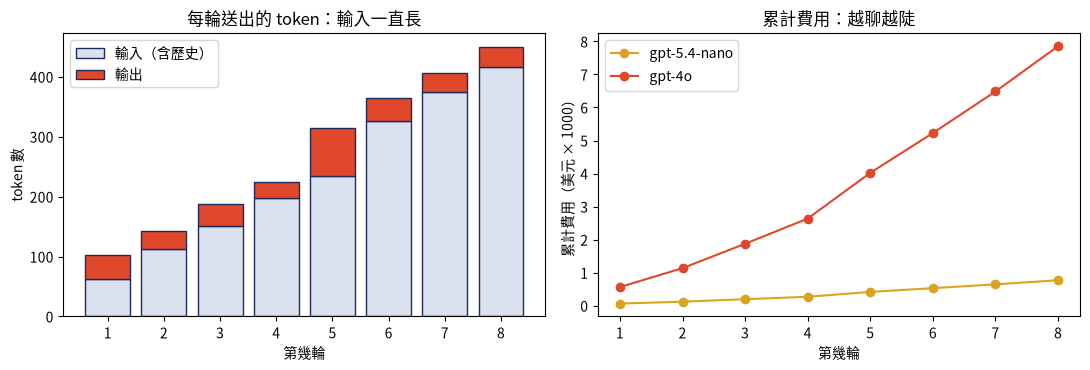

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rounds = np.arange(1, len(per_turn) + 1)
axes[0].bar(rounds, [pt for pt, _ in per_turn], color="#d9e1ee", edgecolor="#1f2a5c", label="輸入（含歷史）")
axes[0].bar(rounds, [ct for _, ct in per_turn], bottom=[pt for pt, _ in per_turn], color="#e0482c", edgecolor="#1f2a5c", label="輸出")
axes[0].set_xlabel("第幾輪")
axes[0].set_ylabel("token 數")
axes[0].set_title("每輪送出的 token：輸入一直長")
axes[0].legend()
for m, color in [(CLOUD_MODEL, "#d9a520"), ("gpt-4o", "#e0482c")]:
    cum = np.cumsum([hand_cost(m, pt, ct) for pt, ct in per_turn]) * 1000
    axes[1].plot(rounds, cum, marker="o", color=color, label=m)
axes[1].set_xlabel("第幾輪")
axes[1].set_ylabel("累計費用（美元 × 1000）")
axes[1].set_title("累計費用：越聊越陡")
axes[1].legend()
plt.tight_layout()
plt.show()

一次對話才幾分之一美分，看起來不多；但一個 agent 一次任務可能來回幾十輪、每輪帶著工具說明和檢索結果，
再乘上每天幾千個使用者，就是真的錢。對策：只保留最近幾輪、把舊對話摘要起來（模組 5 的 compaction）、固定前綴吃快取。

## Step 11：預算追蹤器——超過就停

agent 的迴圈如果卡住，可能在你不知道的時候燒掉一大筆錢。最基本的防護是：每次呼叫前檢查累計花費，超過預算就拒絕。
LiteLLM 有內建的預算功能（`litellm.max_budget`、Proxy 的虛擬金鑰額度），但邏輯很短，自己寫一次最清楚。

這裡實際打的是本機 Ollama，但**用 `gpt-4o` 的價格記帳**，把預算設得很小，才看得到它停下來。

In [13]:
from dataclasses import dataclass, field


class BudgetExceeded(RuntimeError):
    pass


@dataclass
class BudgetTracker:
    budget_usd: float
    price_as: str  # 用哪個模型的價格記帳
    records: tuple = field(default_factory=tuple)  # 每筆 (輸入, 輸出, 費用)，用 tuple 不就地修改

    @property
    def spent(self) -> float:
        return sum(r[2] for r in self.records)

    def complete(self, messages: list[dict], **kwargs):
        estimate = litellm.token_counter(model=self.price_as, messages=messages) * litellm.model_cost[self.price_as]["input_cost_per_token"]
        if self.spent + estimate > self.budget_usd:  # 連輸入都付不起就不送
            raise BudgetExceeded(f"已花 ${self.spent:.6f}，這次輸入至少 ${estimate:.6f}，超過預算 ${self.budget_usd}")
        resp = completion(messages=messages, **kwargs)
        pt, ct = resp.usage.prompt_tokens, resp.usage.completion_tokens
        self.records = (*self.records, (pt, ct, hand_cost(self.price_as, pt, ct)))
        return resp


tracker = BudgetTracker(budget_usd=0.003, price_as="gpt-4o")
characters = ["魯夫", "索隆", "娜美", "騙人布", "香吉士", "喬巴", "羅賓", "佛朗基", "布魯克", "甚平"]
for name in characters:
    try:
        tracker.complete([{"role": "user", "content": f"用三句話介紹{name}。"}],
                         model=LOCAL, api_base=OLLAMA_BASE, max_tokens=120, temperature=0)
        print(f"{name:<4} 這次 ${tracker.records[-1][2]:.6f}   累計 ${tracker.spent:.6f}")
    except BudgetExceeded as exc:
        print(f"{name:<4} 停止：{exc}")
        break

魯夫   這次 $0.000500   累計 $0.000500
索隆   這次 $0.000610   累計 $0.001110
娜美   這次 $0.000440   累計 $0.001550
騙人布  這次 $0.000703   累計 $0.002253
香吉士  這次 $0.000333   累計 $0.002585
喬巴   這次 $0.000520   累計 $0.003105
羅賓   停止：已花 $0.003105，這次輸入至少 $0.000040，超過預算 $0.003


這個追蹤器只擋「送出前」：輸出 token 要等回應才知道，所以最後一次可能稍微超過預算。要擋得更緊，就在送出前
用 `max_tokens` 算出「最壞情況的輸出費用」一起檢查。實務上還會再加一層：在供應商後台設每月上限。

## Step 12：LiteLLM Proxy——把這些搬到一台共用的閘道

上面所有功能（統一介面、fallback、記帳、預算）都在**你的程式裡**。團隊一大，每個服務各寫一次就亂了。
LiteLLM Proxy 是同一套東西包成一個獨立服務（gateway）：

```
各個服務 ──OpenAI 格式──▶ LiteLLM Proxy ──▶ Ollama／OpenAI／Anthropic／…
                         （金鑰集中、fallback、每個團隊的預算與用量報表）
```

- 應用程式只知道 Proxy 的網址和一把「虛擬金鑰」，真正的供應商金鑰只放在 Proxy 上。
- 每把虛擬金鑰可以設預算和速率上限，用量自動記到資料庫。
- 設定是一份 YAML，內容就是 Step 5 的 `model_list`：

```yaml
model_list:
  - model_name: chat
    litellm_params: {model: ollama/qwen2.5:3b, api_base: http://ollama:11434}
```

部署和維運不在本課範圍；知道「團隊共用模型時，通常前面會擋一台這種閘道」就夠了。

## Step 13：雲端對帳

整本 notebook 實際打了幾次雲端、總共花多少：

In [14]:
total = sum(litellm.completion_cost(completion_response=r) for r in cloud_calls)
print(f"雲端呼叫 {len(cloud_calls)} 次（上限 {MAX_CLOUD_CALLS}），"
      f"共 {sum(r.usage.prompt_tokens for r in cloud_calls)} 輸入、{sum(r.usage.completion_tokens for r in cloud_calls)} 輸出 token")
print(f"總花費 ${total:.6f}（約新台幣 {total * 32:.4f} 元）")

雲端呼叫 7 次（上限 8），共 276 輸入、498 輸出 token
總花費 $0.000678（約新台幣 0.0217 元）


## 試試看

1. 在 Step 2 把 OpenAI 的模型換成 `gpt-4o`，對照 Step 3 的費用差幾倍，回答品質差多少？（會多一次雲端呼叫。）
2. 改寫 Step 11 的 `BudgetTracker`：送出前用 `max_tokens` 估最壞情況的輸出費用，確保永遠不會超過預算。
3. 在 Step 10 只保留 system 和最近 2 輪對話再送出，重畫累計費用圖，跟原本的比。

## 小結

- LiteLLM 用「`供應商/模型`」一個字串切換供應商，回應和錯誤都統一成 OpenAI 的格式；`Router` 用設定做 fallback。CrewAI 等框架底層就是它。
- 費用＝輸入 token × 輸入單價＋輸出 token × 輸出單價；輸出貴好幾倍，中文比英文多 token，長對話每輪都重付歷史。
- 推理模型的推理 token 看不到但照輸出計費，`reasoning_effort` 依題目難度調，`max_tokens` 要留空間給推理。
- 每次呼叫記帳、超過預算就停，是 agent 上線前的基本防護。模組 1 到這裡結束；模組 2 開始教怎麼把 prompt 寫好、讓輸出變成程式能用的格式。